# SimulaHub · Módulo 1 – CFD e Modelagem Hemodinâmica
## Dia 2 (04/11) – Fluido real: viscosidade, Reynolds e Navier–Stokes
**Atividade prática da tarde** · Docente: Profª. Drª. Rita de Cássia dos Anjos (UFSCar) · Tutor: Willian Costa de Paula (UTFPR)

---

**Pergunta-guia do curso:** *como a geometria de um vaso influencia o fluxo sanguíneo?*

No Dia 1, o fluido era **ideal**. Hoje ele ganha **viscosidade**. Neste notebook vamos:

1. Calcular forças viscosas: $F = \eta v A / z$.
2. Calcular o **número de Reynolds**, $Re = \rho v D / \eta$, e identificar regimes de escoamento.
3. Visualizar o **perfil de Poiseuille**, $v(r) = \dfrac{\Delta P}{4\eta L}(R^2 - r^2)$.
4. Explorar o **efeito do raio**, $Q = \dfrac{\pi R^4 \Delta P}{8 \eta L}$.
5. Comparar vasos do corpo humano.
6. Explorar os parâmetros de forma interativa.
7. Fazer nossa **primeira simulação numérica**: resolver a equação do escoamento passo a passo no tempo, como um código de CFD faz.

Ao final há **4 exercícios para entregar**.

### Como usar
- Execute as células **em ordem** com `Shift + Enter`. Cada linha de código tem um comentário (após `#`) explicando o que faz.
- Se algo der errado: **Ambiente de execução → Reiniciar e executar tudo**.
- Notação: usamos $\eta$ (como no Tipler) para a viscosidade dinâmica; em CFD é comum usar $\mu$. É a mesma grandeza.

## 0. Preparação: bibliotecas e constantes

In [1]:
import numpy as np                        # NumPy: cálculos numéricos com vetores
import matplotlib.pyplot as plt           # Matplotlib: gráficos

plt.rcParams["figure.figsize"] = (8, 5)   # tamanho padrão das figuras (polegadas)
plt.rcParams["font.size"] = 12            # tamanho padrão das fontes
plt.rcParams["axes.grid"] = True          # grade de fundo nos gráficos

rho = 1060.0        # massa específica do sangue (kg/m³)
eta = 4.0e-3        # viscosidade do sangue a 37 °C (Pa·s) = 4,0 mPa·s
MMHG = 133.322      # 1 mmHg em pascal

def pa_para_mmhg(p):          # converte pascal em mmHg
    return p / MMHG

print(f"Sangue: ρ = {rho} kg/m³, η = {eta*1e3} mPa·s")   # mostra os valores usados

Sangue: ρ = 1060.0 kg/m³, η = 4.0 mPa·s


---
## 1. Viscosidade: o atrito interno

Entre duas placas separadas por $z$, com a de cima movendo-se a $v$, a força necessária é

$$F = \eta \frac{v A}{z}.$$

Vamos comparar fluidos do dia a dia (valores típicos, em Pa·s; o mel varia muito).

Ar (20 °C)              : F = 3.60e-06 N
Água (20 °C)            : F = 2.00e-04 N
Sangue (37 °C)          : F = 8.00e-04 N
Óleo de motor (30 °C)   : F = 4.00e-02 N
Glicerina (20 °C)       : F = 2.82e-01 N
Mel (típico)            : F = 2.00e+00 N


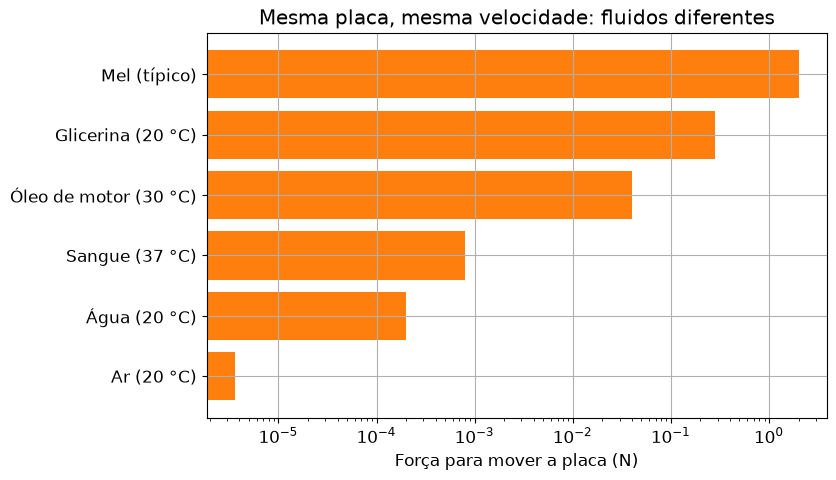

In [2]:
fluidos = {                       # dicionário: nome do fluido -> viscosidade (Pa·s)
    "Ar (20 °C)": 1.8e-5,
    "Água (20 °C)": 1.0e-3,
    "Sangue (37 °C)": 4.0e-3,
    "Óleo de motor (30 °C)": 0.20,
    "Glicerina (20 °C)": 1.41,
    "Mel (típico)": 10.0,
}

A = 0.10 * 0.10     # área da placa: 10 cm × 10 cm, em m²
v = 0.02            # velocidade da placa: 2 cm/s, em m/s
z = 1.0e-3          # espessura da camada de fluido: 1 mm, em m

nomes = list(fluidos.keys())                          # lista com os nomes
F = np.array([fluidos[n] * v * A / z for n in nomes]) # F = η v A / z para cada fluido

for n, f in zip(nomes, F):                            # percorre nomes e forças
    print(f"{n:24s}: F = {f:.2e} N")                  # mostra a força em notação científica

plt.barh(nomes, F, color="tab:orange")                # gráfico de barras horizontais
plt.xscale("log")                                     # escala logarítmica: os valores variam muito
plt.xlabel("Força para mover a placa (N)")            # rótulo do eixo x
plt.title("Mesma placa, mesma velocidade: fluidos diferentes")   # título
plt.show()                                            # exibe

**Interpretação:** a força é proporcional a $\eta$. Entre o ar e o mel há um fator de quase um milhão. O sangue é cerca de 4 vezes mais viscoso que a água.

---
## 2. Número de Reynolds: inércia × viscosidade

$$Re = \frac{\rho v D}{\eta}$$

Em tubos: $Re < 2000$ → laminar; $2000 < Re < 3000$ → instável; $Re > 3000$ → turbulento.

In [3]:
def reynolds(rho, v, D, eta):        # define a função do número de Reynolds
    return rho * v * D / eta         # Re = ρ v D / η (adimensional)

# Exemplo do Tipler: aorta de raio 1,0 cm, v = 30 cm/s
Re_aorta = reynolds(rho, 0.30, 0.020, eta)          # D = 2 × raio = 0,020 m
print(f"Re na aorta (v = 30 cm/s, D = 2 cm): {Re_aorta:.0f}")   # ≈ 1590

# Com os números do Dia 1: Q = 5 L/min, raio 1,25 cm
Q = 5.0e-3 / 60                       # vazão em m³/s
R_aorta = 1.25e-2                     # raio em m
v_aorta = Q / (np.pi * R_aorta**2)    # velocidade média pela continuidade
Re1 = reynolds(rho, v_aorta, 2*R_aorta, eta)        # Re correspondente
print(f"v na aorta = {v_aorta*100:.1f} cm/s  ->  Re = {Re1:.0f}")

Re na aorta (v = 30 cm/s, D = 2 cm): 1590
v na aorta = 17.0 cm/s  ->  Re = 1125


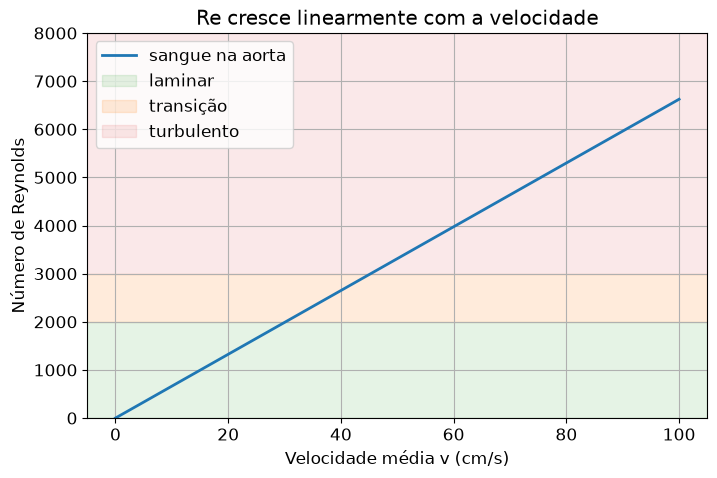

Re atinge 2000 na aorta para v ≈ 30 cm/s


In [4]:
v = np.linspace(0, 1.0, 300)                   # velocidades de 0 a 1 m/s
D = 2 * R_aorta                                 # diâmetro da aorta

plt.plot(v*100, reynolds(rho, v, D, eta), lw=2, label="sangue na aorta")   # Re × v
plt.axhspan(0, 2000, color="tab:green", alpha=0.12, label="laminar")       # faixa laminar
plt.axhspan(2000, 3000, color="tab:orange", alpha=0.15, label="transição") # faixa de transição
plt.axhspan(3000, 8000, color="tab:red", alpha=0.10, label="turbulento")   # faixa turbulenta
plt.ylim(0, 8000)                                # limita o eixo y
plt.xlabel("Velocidade média v (cm/s)")          # rótulo x
plt.ylabel("Número de Reynolds")                 # rótulo y
plt.title("Re cresce linearmente com a velocidade")   # título
plt.legend(loc="upper left")                     # legenda
plt.show()                                       # exibe

v_crit = 2000 * eta / (rho * D)                  # velocidade em que Re = 2000
print(f"Re atinge 2000 na aorta para v ≈ {v_crit*100:.0f} cm/s")

### 2.1 Reynolds na garganta de uma estenose
Pela continuidade, $v_2 = v_1/(1-s)^2$, e o diâmetro é $D_2 = (1-s)D_1$. Então

$$Re_2 = \frac{\rho v_2 D_2}{\eta} = \frac{Re_1}{1-s}.$$

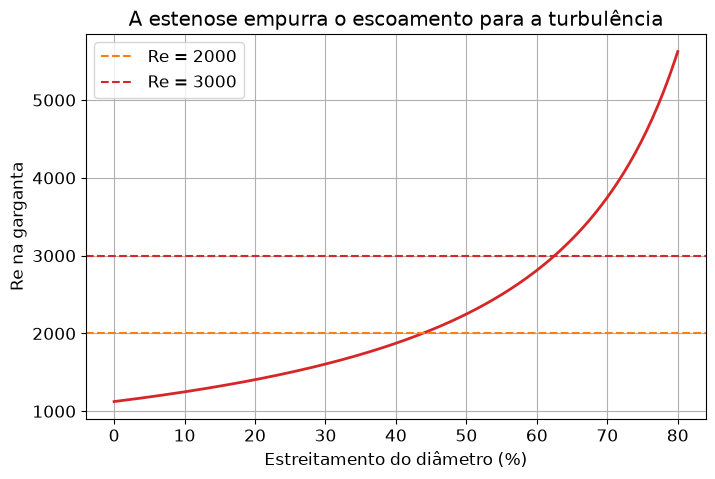

30%: Re na garganta ≈ 1607
50%: Re na garganta ≈ 2249
70%: Re na garganta ≈ 3749


In [5]:
s = np.linspace(0, 0.8, 200)          # fração de redução do diâmetro: 0% a 80%
Re2 = Re1 / (1 - s)                   # Reynolds na garganta

plt.plot(s*100, Re2, lw=2, color="tab:red")                    # curva Re2 × estenose
plt.axhline(2000, ls="--", color="tab:orange", label="Re = 2000")   # limiar laminar
plt.axhline(3000, ls="--", color="tab:red", label="Re = 3000")      # limiar turbulento
plt.xlabel("Estreitamento do diâmetro (%)")                     # rótulo x
plt.ylabel("Re na garganta")                                    # rótulo y
plt.title("A estenose empurra o escoamento para a turbulência") # título
plt.legend()                                                    # legenda
plt.show()                                                      # exibe

for si in [0.3, 0.5, 0.7]:                                      # cenários do curso
    print(f"{int(si*100)}%: Re na garganta ≈ {Re1/(1-si):.0f}")

**Interpretação:** o diâmetro diminui, mas a velocidade aumenta muito mais, então $Re$ cresce. Com 70%, $Re$ passa de 3000: o jato depois da garganta tende a ficar turbulento. É o "sopro" que o médico escuta.

---
## 3. O perfil de Poiseuille

Para um tubo reto de raio $R$ e comprimento $L$, em escoamento laminar e estacionário:

$$v(r) = \frac{\Delta P}{4\eta L}\left(R^2 - r^2\right), \qquad v_{max} = \frac{\Delta P R^2}{4\eta L}, \qquad v_{média} = \frac{v_{max}}{2}.$$

Vamos escolher o gradiente de pressão $\Delta P/L$ que produz a vazão da aorta.

ΔP/L necessário: 34.8 Pa/m  (0.0261 mmHg a cada 10 cm)


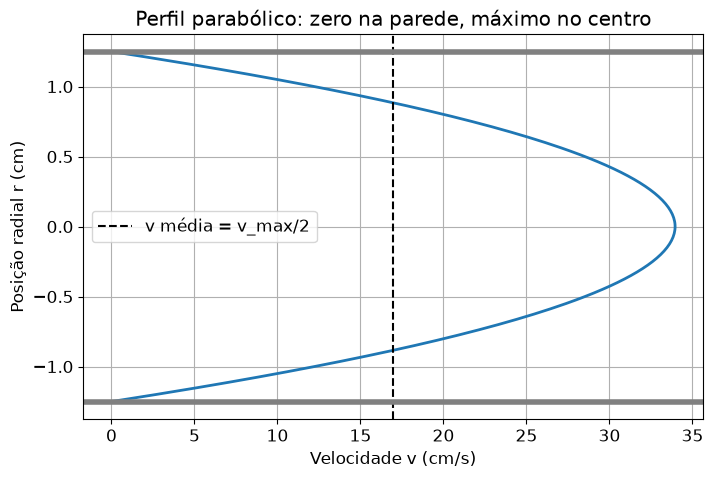

v_max = 34.0 cm/s ; v_média = 17.0 cm/s


In [6]:
G = 8 * eta * Q / (np.pi * R_aorta**4)     # gradiente ΔP/L (Pa/m) que dá a vazão Q, por Poiseuille
print(f"ΔP/L necessário: {G:.1f} Pa/m  ({pa_para_mmhg(G)*0.1:.4f} mmHg a cada 10 cm)")

def v_poiseuille(r, R, G, eta):            # perfil de velocidade de Poiseuille
    return G / (4 * eta) * (R**2 - r**2)    # v(r) = (ΔP/L)(R² − r²)/(4η)

r = np.linspace(-R_aorta, R_aorta, 201)    # posições radiais de −R a +R (atravessa o tubo)
vr = v_poiseuille(r, R_aorta, G, eta)      # velocidade em cada posição

plt.plot(vr*100, r*100, lw=2)                                # velocidade no eixo x, posição no eixo y
plt.axvline(vr.max()/2*100, ls="--", color="k", label="v média = v_max/2")   # velocidade média
plt.axhline(R_aorta*100, color="gray", lw=4)                 # parede superior
plt.axhline(-R_aorta*100, color="gray", lw=4)                # parede inferior
plt.xlabel("Velocidade v (cm/s)")                            # rótulo x
plt.ylabel("Posição radial r (cm)")                          # rótulo y
plt.title("Perfil parabólico: zero na parede, máximo no centro")   # título
plt.legend()                                                 # legenda
plt.show()                                                   # exibe

print(f"v_max = {vr.max()*100:.1f} cm/s ; v_média = {v_aorta*100:.1f} cm/s")   # confere: v_max = 2 v_média

### 3.1 Vendo o perfil na seção transversal
Olhando o tubo "de frente", a velocidade forma anéis: máxima no centro, nula na parede.

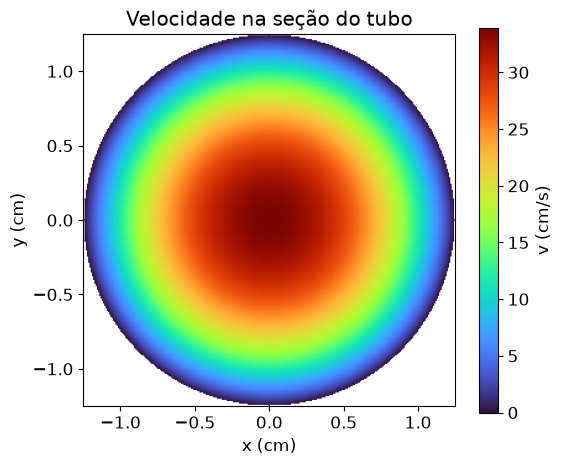

In [7]:
x = np.linspace(-R_aorta, R_aorta, 301)       # coordenada x da seção (m)
X, Y = np.meshgrid(x, x)                       # grade 2D de pontos (x, y)
Rr = np.sqrt(X**2 + Y**2)                      # distância de cada ponto ao centro
Vxy = v_poiseuille(Rr, R_aorta, G, eta)        # velocidade em cada ponto
Vxy[Rr > R_aorta] = np.nan                     # fora do tubo não há fluido: deixamos em branco

plt.figure(figsize=(6, 5))                     # figura quadrada
plt.imshow(Vxy*100, extent=[-1.25, 1.25, -1.25, 1.25], origin="lower", cmap="turbo")   # mapa de cores
plt.colorbar(label="v (cm/s)")                 # barra de cores com unidade
plt.xlabel("x (cm)")                           # rótulo x
plt.ylabel("y (cm)")                           # rótulo y
plt.title("Velocidade na seção do tubo")       # título
plt.grid(False)                                # sem grade sobre a imagem
plt.show()                                     # exibe

---
## 4. O efeito do raio: $Q \propto R^4$

$$Q = \frac{\pi R^4 \Delta P}{8\eta L}$$

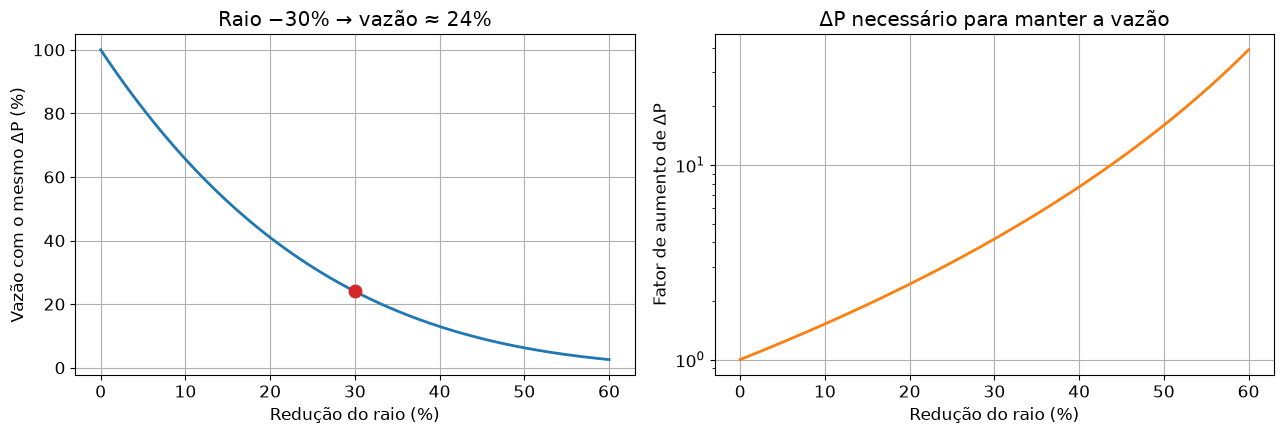

Raio −30%: vazão = 24% ; ΔP precisa ser 4.2× maior


In [8]:
reducao = np.linspace(0, 0.6, 200)          # redução do raio de 0% a 60%
Q_rel = (1 - reducao)**4                    # vazão relativa com o mesmo ΔP
dP_rel = 1 / Q_rel                          # fator de aumento de ΔP para manter Q

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))             # dois gráficos lado a lado
ax[0].plot(reducao*100, Q_rel*100, lw=2)                    # vazão relativa (%)
ax[0].plot(30, 0.7**4*100, "o", ms=9, color="tab:red")      # destaca 30% de redução
ax[0].set_xlabel("Redução do raio (%)")                     # rótulo x
ax[0].set_ylabel("Vazão com o mesmo ΔP (%)")                # rótulo y
ax[0].set_title("Raio −30% → vazão ≈ 24%")                  # título
ax[1].semilogy(reducao*100, dP_rel, lw=2, color="tab:orange")   # fator de ΔP em escala log
ax[1].set_xlabel("Redução do raio (%)")                     # rótulo x
ax[1].set_ylabel("Fator de aumento de ΔP")                  # rótulo y
ax[1].set_title("ΔP necessário para manter a vazão")        # título
plt.tight_layout()                                          # ajusta espaçamentos
plt.show()                                                  # exibe

print(f"Raio −30%: vazão = {0.7**4*100:.0f}% ; ΔP precisa ser {1/0.7**4:.1f}× maior")

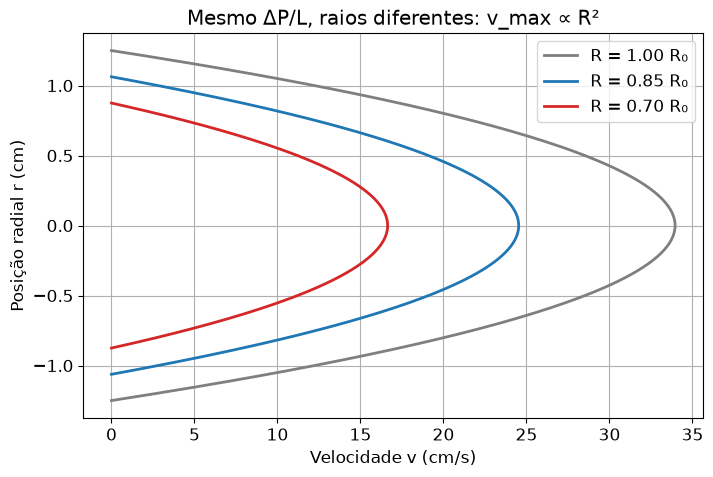

In [9]:
r_ax = np.linspace(-1, 1, 201)                          # posição radial adimensional r/R
for f, c in zip([1.0, 0.85, 0.7], ["tab:gray", "tab:blue", "tab:red"]):   # três raios relativos
    Rf = f * R_aorta                                    # raio do tubo
    rr = r_ax * Rf                                      # posições reais
    plt.plot(v_poiseuille(rr, Rf, G, eta)*100, rr*100, lw=2, color=c, label=f"R = {f:.2f} R₀")  # perfil
plt.xlabel("Velocidade v (cm/s)")                       # rótulo x
plt.ylabel("Posição radial r (cm)")                     # rótulo y
plt.title("Mesmo ΔP/L, raios diferentes: v_max ∝ R²")   # título
plt.legend()                                            # legenda
plt.show()                                              # exibe

**Interpretação:** com o mesmo gradiente de pressão, o tubo mais fino tem velocidade máxima menor ($\propto R^2$) **e** área menor ($\propto R^2$): a vazão cai com $R^4$.

---
## 5. Comparando vasos do corpo
Como $Q = \pi R^2 v_{média}$, a queda de pressão por comprimento é

$$\frac{\Delta P}{L} = \frac{8 \eta\, v_{média}}{R^2}.$$

Valores de raio e velocidade abaixo são **ilustrativos** (ordens de grandeza).

Vaso           |        Re |  ΔP por cm (mmHg)
Aorta          |  1.13e+03 |             0.003
Artéria média  |  1.06e+02 |             0.060
Arteríola      |  3.97e-02 |            53.338
Capilar        |  1.06e-03 |            75.006


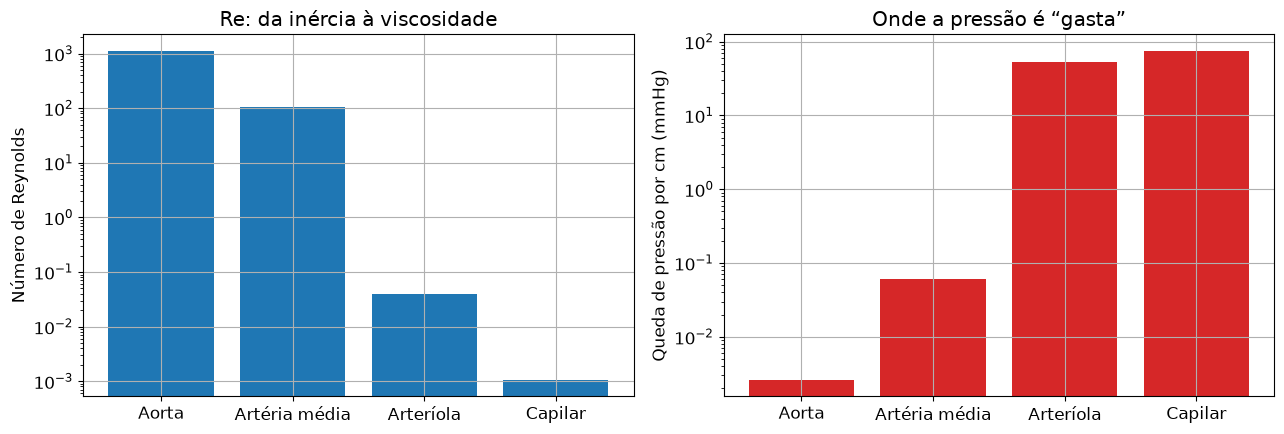

In [10]:
vasos = {                               # nome: (raio em m, velocidade média em m/s), valores ilustrativos
    "Aorta":       (1.25e-2, 0.17),
    "Artéria média": (2.0e-3, 0.10),
    "Arteríola":   (15e-6, 5e-3),
    "Capilar":     (4e-6, 5e-4),
}

print(f"{'Vaso':14s} | {'Re':>9s} | {'ΔP por cm (mmHg)':>17s}")      # cabeçalho
nomes, Res, dPs = [], [], []                                          # listas para os gráficos
for nome, (Rv, vv) in vasos.items():                                  # percorre os vasos
    Re_v = reynolds(rho, vv, 2*Rv, eta)                               # Reynolds
    dP_cm = 8 * eta * vv / Rv**2 * 0.01                               # ΔP em 1 cm (Pa)
    nomes.append(nome); Res.append(Re_v); dPs.append(pa_para_mmhg(dP_cm))   # guarda os valores
    print(f"{nome:14s} | {Re_v:9.2e} | {pa_para_mmhg(dP_cm):17.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))       # dois gráficos
ax[0].bar(nomes, Res, color="tab:blue"); ax[0].set_yscale("log")      # Re em escala log
ax[0].set_ylabel("Número de Reynolds"); ax[0].set_title("Re: da inércia à viscosidade")
ax[1].bar(nomes, dPs, color="tab:red"); ax[1].set_yscale("log")       # ΔP por cm em escala log
ax[1].set_ylabel("Queda de pressão por cm (mmHg)"); ax[1].set_title("Onde a pressão é “gasta”")
plt.tight_layout(); plt.show()                       # ajusta e exibe

**Interpretação:** na aorta, $Re$ é alto e quase não se perde pressão. Nas arteríolas e capilares, $Re \ll 1$ e a queda de pressão por centímetro é milhares de vezes maior: é ali que está a resistência do sistema circulatório. (Arteríolas e capilares são curtos, da ordem de milímetros, então a queda em cada vaso é menor que o valor “por cm”; o que a tabela compara é a resistência por comprimento.)

---
## 6. Exploração interativa
Mova os controles e observe o perfil, a vazão e o número de Reynolds.

In [11]:
from ipywidgets import interact, FloatSlider          # controles interativos

def explorar(R_mm=12.5, eta_mPas=4.0, G_Pa_m=20.0):
    Rv = R_mm * 1e-3                                  # raio em m
    et = eta_mPas * 1e-3                              # viscosidade em Pa·s
    rr = np.linspace(-Rv, Rv, 201)                    # posições radiais
    vv = v_poiseuille(rr, Rv, G_Pa_m, et)             # perfil
    Qv = np.pi * Rv**4 * G_Pa_m / (8 * et)            # vazão de Poiseuille
    vm = Qv / (np.pi * Rv**2)                         # velocidade média
    Re_v = reynolds(rho, vm, 2*Rv, et)                # Reynolds
    regime = "laminar" if Re_v < 2000 else ("transição" if Re_v < 3000 else "turbulento*")
    plt.plot(vv*100, rr*1000, lw=2)                   # perfil (cm/s × mm)
    plt.xlabel("v (cm/s)"); plt.ylabel("r (mm)")      # rótulos
    plt.title(f"Q = {Qv*6e4:.2f} L/min · Re = {Re_v:.0f} ({regime})")   # vazão e Re no título
    plt.show()                                        # exibe
    if Re_v >= 2000:
        print("*Poiseuille só vale no regime laminar: aqui o perfil real seria diferente.")

interact(explorar,
         R_mm=FloatSlider(min=1, max=15, step=0.5, value=12.5, description="R (mm)"),
         eta_mPas=FloatSlider(min=1, max=10, step=0.5, value=4.0, description="η (mPa·s)"),
         G_Pa_m=FloatSlider(min=1, max=100, step=1, value=20, description="ΔP/L (Pa/m)"));

interactive(children=(FloatSlider(value=12.5, description='R (mm)', max=15.0, min=1.0, step=0.5), FloatSlider(…

---
## 7. Nossa primeira simulação numérica

Até aqui usamos a **fórmula** de Poiseuille. Agora vamos obtê-la **numericamente**, como um código de CFD faria. Para simplificar, usamos o escoamento entre duas placas paralelas em $y = \pm h$ (o "primo" 2D do tubo). A equação de Navier–Stokes nessa geometria se reduz a

$$\rho \frac{\partial v}{\partial t} = G + \eta \frac{\partial^2 v}{\partial y^2}, \qquad G = \frac{\Delta P}{L}.$$

Começamos com o fluido **parado** e "ligamos" o gradiente de pressão. O fluido acelera até atingir o regime estacionário, cuja solução exata é $v(y) = \dfrac{G}{2\eta}(h^2 - y^2)$.

**Ingredientes de uma simulação (que veremos no SimVascular):**
- **Malha:** dividimos o domínio em $N$ pontos.
- **Condições de contorno:** $v = 0$ nas paredes (não deslizamento).
- **Passo de tempo** $\Delta t$ e **iterações**.
- **Convergência:** paramos quando a solução não muda mais.

In [12]:
h = 0.01                  # meia distância entre as placas: 1 cm (m)
N = 51                    # número de pontos da malha
y = np.linspace(-h, h, N) # posições dos pontos (malha uniforme)
dy = y[1] - y[0]          # espaçamento da malha
nu = eta / rho            # viscosidade cinemática ν = η/ρ (m²/s)
Gs = 16.0                 # gradiente de pressão ΔP/L (Pa/m)

dt = 0.4 * dy**2 / nu     # passo de tempo: abaixo do limite de estabilidade dy²/(2ν)
print(f"Δy = {dy*1e3:.2f} mm ; Δt = {dt*1e3:.2f} ms")

v = np.zeros(N)           # condição inicial: fluido parado
v_exato = Gs / (2 * eta) * (h**2 - y**2)   # solução estacionária exata, para comparar

instantes = [1, 5, 10, 20, 40]             # tempos (s) em que vamos guardar o perfil
perfis = {}                                # dicionário para guardar os perfis
residuos = []                              # mudança da solução a cada passo (convergência)
t = 0.0                                    # tempo inicial
passo = 0                                  # contador de iterações

while t < 120:                                                 # simula até 120 s
    lap = np.zeros(N)                                          # vetor para ∂²v/∂y²
    lap[1:-1] = (v[2:] - 2*v[1:-1] + v[:-2]) / dy**2           # diferença finita centrada nos pontos internos
    v_novo = v + dt * (Gs/rho + nu * lap)                      # avança no tempo: método de Euler explícito
    v_novo[0] = 0.0; v_novo[-1] = 0.0                          # não deslizamento nas paredes
    residuos.append(np.max(np.abs(v_novo - v)))                # quanto a solução mudou neste passo
    v = v_novo                                                 # atualiza a solução
    t += dt; passo += 1                                        # avança tempo e contador
    for ti in instantes:                                       # guarda o perfil nos instantes escolhidos
        if ti not in perfis and t >= ti:
            perfis[ti] = v.copy()

print(f"Iterações: {passo} ; erro máximo final em relação à solução exata: {np.max(np.abs(v - v_exato))*100:.4f} cm/s")

Δy = 0.40 mm ; Δt = 16.96 ms
Iterações: 7076 ; erro máximo final em relação à solução exata: 0.0003 cm/s


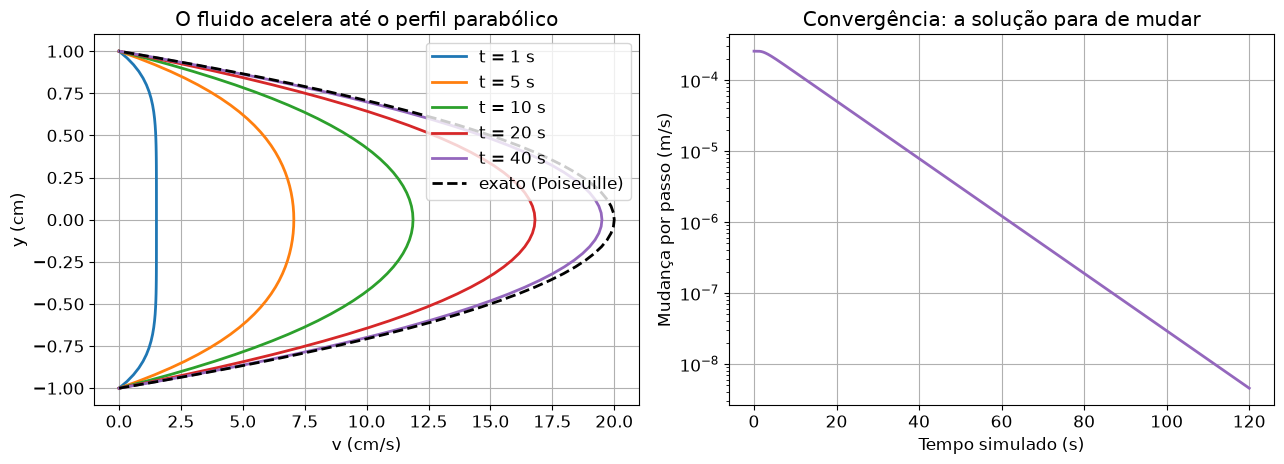

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))       # dois gráficos

for ti, pf in perfis.items():                         # perfis guardados
    ax[0].plot(pf*100, y*100, lw=2, label=f"t = {ti} s")   # perfil em cm/s × cm
ax[0].plot(v_exato*100, y*100, "k--", lw=2, label="exato (Poiseuille)")   # solução exata
ax[0].set_xlabel("v (cm/s)"); ax[0].set_ylabel("y (cm)")                  # rótulos
ax[0].set_title("O fluido acelera até o perfil parabólico")               # título
ax[0].legend()                                                            # legenda

ax[1].semilogy(np.arange(1, passo+1)*dt, residuos, lw=2, color="tab:purple")   # resíduo × tempo
ax[1].set_xlabel("Tempo simulado (s)"); ax[1].set_ylabel("Mudança por passo (m/s)")   # rótulos
ax[1].set_title("Convergência: a solução para de mudar")                  # título
plt.tight_layout(); plt.show()                                            # exibe

**Interpretação:**
- À esquerda: a simulação começa com o fluido parado e chega exatamente à parábola de Poiseuille. Você acabou de resolver numericamente um caso particular de Navier–Stokes.
- À direita: o **resíduo** cai com o tempo; quando fica muito pequeno, dizemos que a simulação **convergiu**. No SimVascular, você verá curvas de resíduo como esta.
- A escala de tempo do problema é $h^2/\nu \approx 26$ s; a solução precisa de alguns múltiplos disso para convergir completamente. Com um fluido mais viscoso, esse tempo seria menor.

---
## Resumo do dia
| Conceito | Equação | O que vimos |
|---|---|---|
| Viscosidade | $F = \eta v A/z$ | sangue ≈ 4 × água; mel ≈ 10⁴ × água |
| Reynolds | $Re = \rho v D/\eta$ | aorta ≈ 10³; capilar ≈ 10⁻³; estenose aumenta $Re$ |
| Poiseuille | $v(r) = \frac{\Delta P}{4\eta L}(R^2 - r^2)$ | perfil parabólico, $v_{média} = v_{max}/2$ |
| Efeito do raio | $Q \propto R^4$ | raio −30% → vazão 24% |
| Simulação | $\rho\,\partial_t v = G + \eta\,\partial_y^2 v$ | malha, passo de tempo, convergência |

**Resultado esperado do dia:** compreender por que a viscosidade é essencial, identificar regimes de escoamento e qual é o papel da equação de Navier–Stokes.

---
# Exercícios para entregar

**Instruções de entrega**
- Resolva cada exercício nas células indicadas (crie células novas se precisar).
- Todos os gráficos com **eixos rotulados com unidades** e título.
- Respostas discursivas em células de texto.
- Ao terminar: **Ambiente de execução → Reiniciar e executar tudo**, para conferir que roda sem erros.
- Baixe em **Arquivo → Fazer download → Fazer download do .ipynb**, nomeie como `NomeSobrenome_Dia2.ipynb` e envie até **[prazo a definir pela docente]**.

### Exercício 1 – Viscosímetro de placas
Duas placas estão separadas por **0,5 mm** de fluido. A placa de cima, de **20 cm × 20 cm**, move-se a **5,0 cm/s**.

a) Calcule a força necessária para água (20 °C), sangue (37 °C), óleo de motor (30 °C, η = 0,20 Pa·s) e glicerina (20 °C, η = 1,41 Pa·s). Use os valores da Seção 1.

b) Faça um gráfico de barras das forças em escala logarítmica.

c) Para o **sangue**, qual deveria ser a velocidade da placa para que a força fosse de 1 mN? Responda numericamente e comente se é uma velocidade "do dia a dia".

Item (a) – Forças necessárias para mover a placa a 5 cm/s:
Água (20 °C)            : F =     0.0040 N  (     4.0 mN)
Sangue (37 °C)          : F =     0.0160 N  (    16.0 mN)
Óleo de motor (30 °C)   : F =     0.8000 N  (   800.0 mN)
Glicerina (20 °C)       : F =     5.6400 N  (  5640.0 mN)


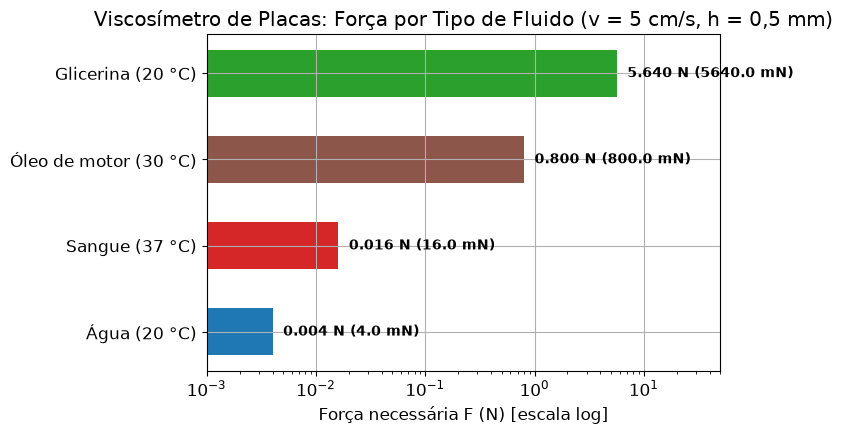


Item (c) – Sangue com F = 1 mN:
Velocidade necessária: v = 0.003125 m/s = 0.3125 cm/s = 3.125 mm/s


In [14]:
# Exercício 1 – Resolução dos itens (a) e (b)

# Parâmetros geométricos e cinemáticos
z_gap = 0.5e-3        # distância entre as placas: 0,5 mm em m
A_placa = 0.20 * 0.20 # placa de 20 cm x 20 cm em m² = 0,04 m²
v_placa = 0.05        # velocidade de 5,0 cm/s em m/s

# Viscosidades (Pa·s)
fluidos_ex1 = {
    'Água (20 °C)': 1.0e-3,
    'Sangue (37 °C)': 4.0e-3,
    'Óleo de motor (30 °C)': 0.20,
    'Glicerina (20 °C)': 1.41,
}

nomes_ex1 = list(fluidos_ex1.keys())
forcas_ex1 = np.array([fluidos_ex1[n] * v_placa * A_placa / z_gap for n in nomes_ex1])

print('Item (a) – Forças necessárias para mover a placa a 5 cm/s:')
for n, f in zip(nomes_ex1, forcas_ex1):
    print(f'{n:24s}: F = {f:10.4f} N  ({f*1e3:8.1f} mN)')

# b) Gráfico de barras das forças em escala logarítmica
plt.figure(figsize=(8, 4.5))
barras = plt.barh(nomes_ex1, forcas_ex1, color=['tab:blue', 'tab:red', 'tab:brown', 'tab:green'], height=0.55)
plt.xscale('log')
plt.xlabel('Força necessária F (N) [escala log]')
plt.title('Viscosímetro de Placas: Força por Tipo de Fluido (v = 5 cm/s, h = 0,5 mm)')
for b, f in zip(barras, forcas_ex1):
    plt.text(f * 1.25, b.get_y() + b.get_height()/2, f'{f:.3f} N ({f*1e3:.1f} mN)', 
             va='center', fontsize=10, fontweight='bold')
plt.xlim(1e-3, 50)
plt.tight_layout()
plt.show()

# c) Cálculo da velocidade para o sangue com F = 1 mN
F_alvo = 1.0e-3       # 1 mN em N
eta_sangue = fluidos_ex1['Sangue (37 °C)']
v_alvo = (F_alvo * z_gap) / (eta_sangue * A_placa)
print(f'\nItem (c) – Sangue com F = 1 mN:')
print(f'Velocidade necessária: v = {v_alvo:.6f} m/s = {v_alvo*100:.4f} cm/s = {v_alvo*1e3:.3f} mm/s')


### Resposta do Exercício 1 (c)

Para que a força exercida sobre a placa pelo sangue seja de exatamente $F = 1{,}0\text{ mN} = 1{,}0\times 10^{-3}\text{ N}$:
$$F = \frac{\eta v A}{z} \implies v = \frac{F \cdot z}{\eta \cdot A}$$
Substituindo os valores numéricos:
$$v = \frac{(1{,}0\times 10^{-3}\text{ N}) \cdot (0{,}5\times 10^{-3}\text{ m})}{(4{,}0\times 10^{-3}\text{ Pa}\cdot\text{s}) \cdot (0{,}04\text{ m}^2)} = \frac{5{,}0\times 10^{-7}}{1{,}6\times 10^{-4}} = \mathbf{3{,}125\times 10^{-3}\text{ m/s}} = \mathbf{0{,}3125\text{ cm/s}} = \mathbf{3{,}125\text{ mm/s}}$$

**Comentário sobre a velocidade:**
Essa velocidade (~3,1 mm/s) é **extremamente baixa** no contexto de movimentos macroscópicos cotidianos (equivale à velocidade de deslocamento de um ponteiro de relógio ou de um inseto caminhando devagar). Uma força de apenas $1\text{ mN}$ é uma força sutilíssima (equivalente ao peso de um miligrama de água, 0,1 mL). Isso demonstra quantitativamente que, em escalas macroscópicas usuais, mesmo um fluido quatro vezes mais viscoso que a água como o sangue oferece uma resistência por atrito viscoso muito suave sob velocidades imperceptíveis.


### Exercício 2 – Água, sangue e turbulência
a) Faça **um único gráfico** de $Re$ em função da velocidade (0 a 1 m/s) para **água** (ρ = 1000 kg/m³, η = 1,0 mPa·s) e **sangue** em um tubo de **2,0 cm** de diâmetro, com as faixas laminar/transição/turbulento.

b) Para cada fluido, encontre a velocidade em que $Re = 2000$, analiticamente e marcando no gráfico.

c) Na aorta ($Re_1$ calculado na Seção 2), a partir de qual estreitamento $s$ do diâmetro o $Re$ na garganta passa de 3000? Resolva analiticamente e confirme com um gráfico de $Re_2 \times s$.

Item (b) – Velocidade para Re = 2000 (D = 2 cm):
Água:   v = 0.1000 m/s = 10.00 cm/s
Sangue: v = 0.3774 m/s = 37.74 cm/s


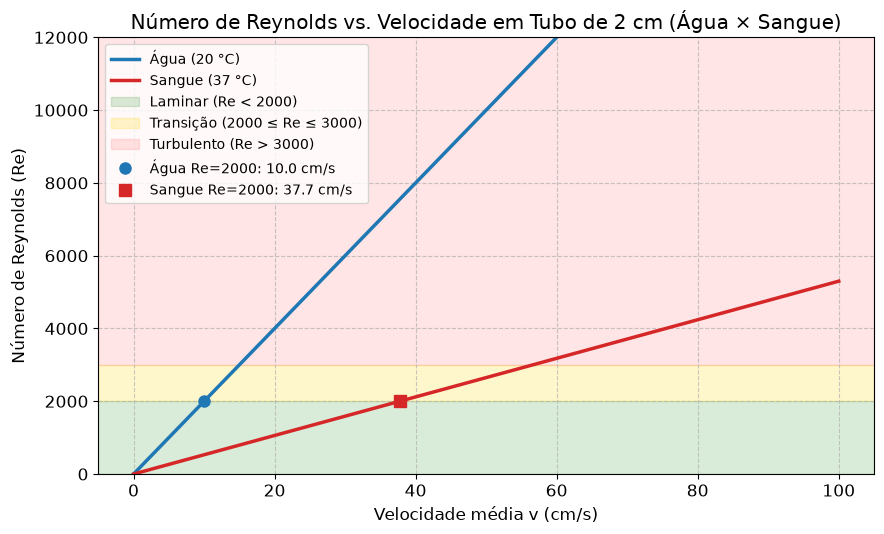


Item (c) – Aorta (Re1 = 1124.7):
Estreitamento para Re2 > 3000: s >= 62.51%


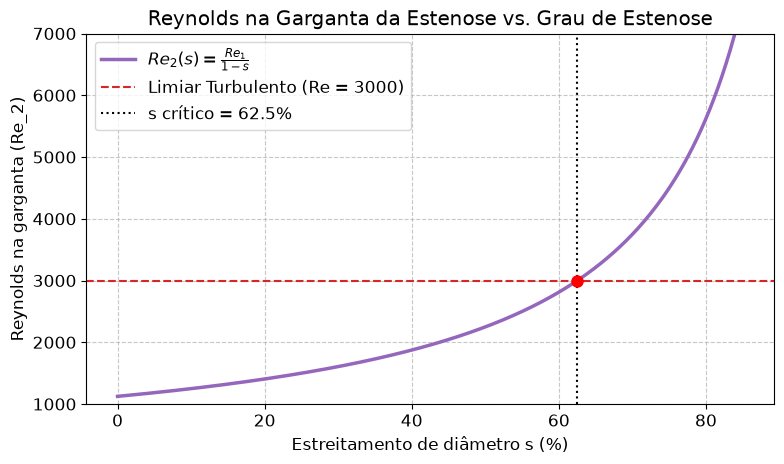

In [15]:
# Exercício 2 – Resolução dos itens (a), (b) e (c)

# Parâmetros
D_tubo = 0.02          # diâmetro de 2,0 cm = 0,02 m
rho_agua, eta_agua = 1000.0, 1.0e-3    # água a 20 °C
rho_sangue, eta_sangue = 1060.0, 4.0e-3 # sangue a 37 °C

v_faixa = np.linspace(0.0, 1.0, 300)   # 0 a 1 m/s
Re_agua = reynolds(rho_agua, v_faixa, D_tubo, eta_agua)
Re_sangue = reynolds(rho_sangue, v_faixa, D_tubo, eta_sangue)

# b) Velocidade analítica para Re = 2000: v = 2000 * eta / (rho * D)
v_crit_agua = 2000.0 * eta_agua / (rho_agua * D_tubo)
v_crit_sangue = 2000.0 * eta_sangue / (rho_sangue * D_tubo)

print('Item (b) – Velocidade para Re = 2000 (D = 2 cm):')
print(f'Água:   v = {v_crit_agua:.4f} m/s = {v_crit_agua*100:.2f} cm/s')
print(f'Sangue: v = {v_crit_sangue:.4f} m/s = {v_crit_sangue*100:.2f} cm/s')

# Gráfico do Item (a) e (b)
plt.figure(figsize=(9, 5.5))
plt.plot(v_faixa * 100, Re_agua, color='tab:blue', lw=2.5, label='Água (20 °C)')
plt.plot(v_faixa * 100, Re_sangue, color='tab:red', lw=2.5, label='Sangue (37 °C)')

# Faixas de escoamento
plt.axhspan(0, 2000, color='green', alpha=0.15, label='Laminar (Re < 2000)')
plt.axhspan(2000, 3000, color='gold', alpha=0.2, label='Transição (2000 ≤ Re ≤ 3000)')
plt.axhspan(3000, 21000, color='red', alpha=0.1, label='Turbulento (Re > 3000)')

plt.plot(v_crit_agua * 100, 2000, 'o', color='tab:blue', ms=8, label=rf'Água Re=2000: {v_crit_agua*100:.1f} cm/s')
plt.plot(v_crit_sangue * 100, 2000, 's', color='tab:red', ms=8, label=rf'Sangue Re=2000: {v_crit_sangue*100:.1f} cm/s')

plt.xlabel('Velocidade média v (cm/s)')
plt.ylabel('Número de Reynolds (Re)')
plt.title('Número de Reynolds vs. Velocidade em Tubo de 2 cm (Água × Sangue)')
plt.ylim(0, 12000)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# c) Estenose na aorta: Re2 = Re1 / (1 - s)
# Re1 com parâmetros da Seção 2 (Q = 5 L/min, R = 1.25 cm)
s_range = np.linspace(0.0, 0.85, 300)
Re2_curva = Re1 / (1.0 - s_range)
s_crit_3000 = 1.0 - Re1 / 3000.0

print(f'\nItem (c) – Aorta (Re1 = {Re1:.1f}):')
print(f'Estreitamento para Re2 > 3000: s >= {s_crit_3000*100:.2f}%')

plt.figure(figsize=(8, 4.8))
plt.plot(s_range * 100, Re2_curva, color='tab:purple', lw=2.5, label=r'$Re_2(s) = \frac{Re_1}{1 - s}$')
plt.axhline(3000, color='tab:red', ls='--', lw=1.5, label='Limiar Turbulento (Re = 3000)')
plt.axvline(s_crit_3000 * 100, color='k', ls=':', lw=1.5, label=f's crítico = {s_crit_3000*100:.1f}%')
plt.plot(s_crit_3000 * 100, 3000, 'ro', ms=8)
plt.xlabel('Estreitamento de diâmetro s (%)')
plt.ylabel('Reynolds na garganta (Re_2)')
plt.title('Reynolds na Garganta da Estenose vs. Grau de Estenose')
plt.ylim(1000, 7000)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### Respostas do Exercício 2 (b) e (c)

#### Resolução Analítica do Item (b):
Pela definição do número de Reynolds em condutos circulares de diâmetro $D = 2{,}0\text{ cm} = 0{,}02\text{ m}$:
$$Re = \frac{\rho v D}{\eta} \implies v = \frac{Re \cdot \eta}{\rho \cdot D}$$
Para o limiar de transição em $Re = 2000$:
1. **Água ($20^\circ\text{C}$):**
   $$v_{\text{crítico, água}} = \frac{2000 \cdot (1{,}0\times 10^{-3}\text{ Pa}\cdot\text{s})}{(1000\text{ kg/m}^3) \cdot (0{,}02\text{ m})} = \frac{2{,}0}{20} = \mathbf{0{,}10\text{ m/s}} = \mathbf{10{,}0\text{ cm/s}}$$
2. **Sangue ($37^\circ\text{C}$):**
   $$v_{\text{crítico, sangue}} = \frac{2000 \cdot (4{,}0\times 10^{-3}\text{ Pa}\cdot\text{s})}{(1060\text{ kg/m}^3) \cdot (0{,}02\text{ m})} = \frac{8{,}0}{21{,}2} \approx \mathbf{0{,}3774\text{ m/s}} = \mathbf{37{,}74\text{ cm/s}}$$
Como o sangue possui viscosidade 4 vezes maior que a água (e densidade apenas 6% superior), sua viscosidade cinemática $\nu = \eta/\rho$ é quase 4 vezes maior, amortecendo perturbações e permitindo velocidades substancialmente superiores antes de transicionar do regime laminar para turbulento.

---

#### Resolução Analítica do Item (c):
Na aorta de referência, com $Q = 5\text{ L/min}$ e raio $R_1 = 1{,}25\text{ cm}$ ($D_1 = 2{,}5\text{ cm} = 0{,}025\text{ m}$):
$$v_1 = \frac{Q}{\pi R_1^2} \approx 0{,}1698\text{ m/s} \implies Re_1 = \frac{\rho v_1 D_1}{\eta} \approx 1125$$
Em uma estenose com redução de diâmetro por fração $s$, pela continuidade $v_2 = v_1 / (1 - s)^2$ e o diâmetro local torna-se $D_2 = D_1 (1 - s)$. Assim:
$$Re_2 = \frac{\rho v_2 D_2}{\eta} = \frac{\rho \cdot \left(\frac{v_1}{(1-s)^2}\right) \cdot [D_1(1-s)]}{\eta} = \frac{\rho v_1 D_1}{\eta (1 - s)} = \frac{Re_1}{1 - s}$$
Para que o escoamento na garganta atinja o regime turbulento ($Re_2 \ge 3000$):
$$\frac{Re_1}{1 - s} \ge 3000 \implies 1 - s \le \frac{Re_1}{3000} \implies s \ge 1 - \frac{Re_1}{3000}$$
Substituindo o valor numérico de $Re_1 \approx 1125$:
$$s \ge 1 - \frac{1125}{3000} = 1 - 0{,}375 = \mathbf{0{,}625} \quad (\mathbf{62{,}5\%})$$
Portanto, a partir de um estreitamento de **62,5% do diâmetro** vascular, o número de Reynolds supera 3000, provocando turbulência com vórtices e vibrações acústicas características (sopro audível ao estetoscópio).


### Exercício 3 – Vasoconstrição e vasodilatação
As arteríolas regulam o fluxo mudando seu raio.

a) Para variações de raio de **−50% a +50%**, faça um gráfico da vazão relativa $Q/Q_0$ (mesmo ΔP) e outro do fator de ΔP necessário para manter $Q_0$.

b) Destaque nos gráficos os casos de **−20%** (vasoconstrição) e **+20%** (vasodilatação) e escreva os valores numéricos.

c) Em poucas linhas: por que o corpo controla o fluxo mudando o **raio** dos vasos, e não a viscosidade do sangue ou o comprimento dos vasos? Use a lei de Poiseuille no argumento.

Item (b) – Valores numéricos específicos:
Vasoconstrição (-20% de raio):
  Vazão relativa Q/Q0:           0.4096 (40.96% de Q0)
  Fator de ΔP para manter Q0:    2.4414x (+144.1%)
Vasodilatação (+20% de raio):
  Vazão relativa Q/Q0:           2.0736 (207.36% de Q0)
  Fator de ΔP para manter Q0:    0.4823x (-51.8%)


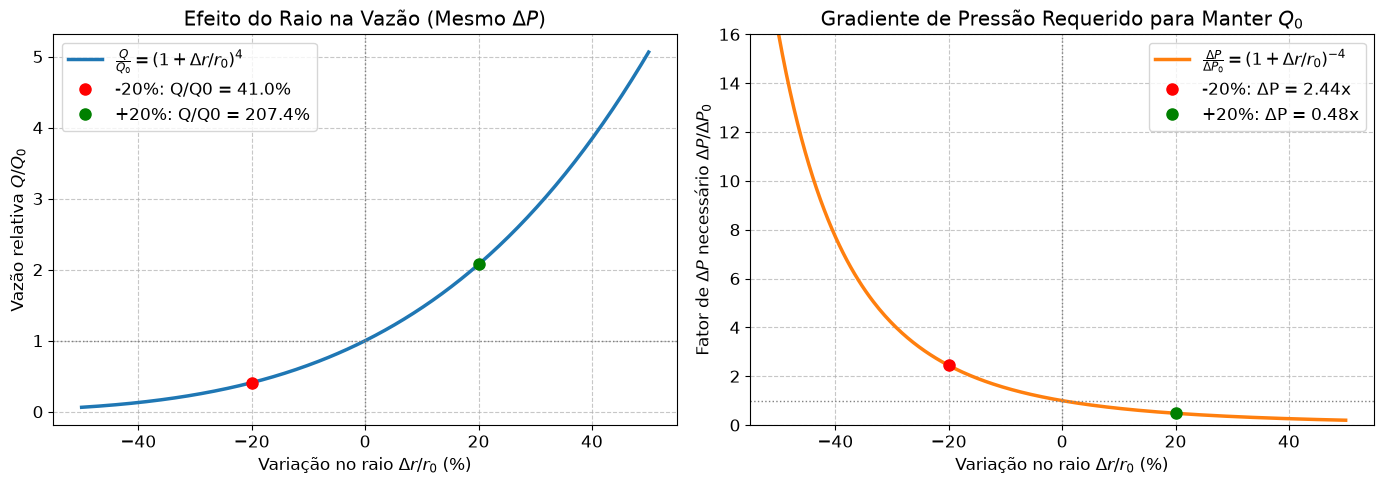

In [16]:
# Exercício 3 – Resolução dos itens (a) e (b)

# Variações percentuais de raio: -50% a +50%
delta_r = np.linspace(-0.50, 0.50, 300)
razao_raio = 1.0 + delta_r     # R / R0

# Pela Lei de Poiseuille: Q = (pi * R^4 * delta_P) / (8 * eta * L)
# Com mesmo delta_P: Q / Q0 = (R / R0)^4
razao_Q = razao_raio**4

# Para manter a mesma vazão Q0: delta_P / delta_P0 = (R0 / R)^4 = 1 / (R / R0)^4
fator_delta_P = 1.0 / (razao_raio**4)

# Casos específicos do Item (b): -20% e +20%
# Vasoconstrição (-20%)
Q_vasoconstricao = (1.0 - 0.20)**4
dP_vasoconstricao = 1.0 / Q_vasoconstricao

# Vasodilatação (+20%)
Q_vasodilatacao = (1.0 + 0.20)**4
dP_vasodilatacao = 1.0 / Q_vasodilatacao

print('Item (b) – Valores numéricos específicos:')
print(f'Vasoconstrição (-20% de raio):')
print(f'  Vazão relativa Q/Q0:           {Q_vasoconstricao:.4f} ({Q_vasoconstricao*100:.2f}% de Q0)')
print(f'  Fator de ΔP para manter Q0:    {dP_vasoconstricao:.4f}x (+{(dP_vasoconstricao-1)*100:.1f}%)')
print(f'Vasodilatação (+20% de raio):')
print(f'  Vazão relativa Q/Q0:           {Q_vasodilatacao:.4f} ({Q_vasodilatacao*100:.2f}% de Q0)')
print(f'  Fator de ΔP para manter Q0:    {dP_vasodilatacao:.4f}x ({(dP_vasodilatacao-1)*100:.1f}%)')

# Gráficos
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Vazão relativa (mesmo ΔP)
ax[0].plot(delta_r * 100, razao_Q, color='tab:blue', lw=2.5, label=r'$\frac{Q}{Q_0} = (1 + \Delta r/r_0)^4$')
ax[0].plot(-20, Q_vasoconstricao, 'ro', ms=8, label=f'-20%: Q/Q0 = {Q_vasoconstricao*100:.1f}%')
ax[0].plot(+20, Q_vasodilatacao, 'go', ms=8, label=f'+20%: Q/Q0 = {Q_vasodilatacao*100:.1f}%')
ax[0].axhline(1.0, color='gray', ls=':', lw=1)
ax[0].axvline(0.0, color='gray', ls=':', lw=1)
ax[0].set_xlabel(r'Variação no raio $\Delta r / r_0$ (%)')
ax[0].set_ylabel('Vazão relativa $Q / Q_0$')
ax[0].set_title(r'Efeito do Raio na Vazão (Mesmo $\Delta P$)')
ax[0].grid(True, linestyle='--', alpha=0.7)
ax[0].legend(frameon=True)

# Gráfico 2: Fator de ΔP necessário para manter Q0
ax[1].plot(delta_r * 100, fator_delta_P, color='tab:orange', lw=2.5, label=r'$\frac{\Delta P}{\Delta P_0} = (1 + \Delta r/r_0)^{-4}$')
ax[1].plot(-20, dP_vasoconstricao, 'ro', ms=8, label=f'-20%: ΔP = {dP_vasoconstricao:.2f}x')
ax[1].plot(+20, dP_vasodilatacao, 'go', ms=8, label=f'+20%: ΔP = {dP_vasodilatacao:.2f}x')
ax[1].axhline(1.0, color='gray', ls=':', lw=1)
ax[1].axvline(0.0, color='gray', ls=':', lw=1)
ax[1].set_xlabel(r'Variação no raio $\Delta r / r_0$ (%)')
ax[1].set_ylabel(r'Fator de $\Delta P$ necessário $\Delta P / \Delta P_0$')
ax[1].set_title('Gradiente de Pressão Requerido para Manter $Q_0$')
ax[1].set_ylim(0, 16)
ax[1].grid(True, linestyle='--', alpha=0.7)
ax[1].legend(frameon=True)

plt.tight_layout()
plt.show()


### Resposta do Exercício 3 (c)

Pela Lei de Hagen-Poiseuille, a resistência hidráulica vascular e a vazão associada são:
$$R_{\text{hid}} = \frac{8 \eta L}{\pi R^4} \implies Q = \frac{\Delta P}{R_{\text{hid}}} = \frac{\pi R^4 \Delta P}{8 \eta L}$$

O organismo regula o fluxo sanguíneo primariamente modificando o **raio ($R$)** das arteríolas devido a três fatores biofísicos determinantes:

1. **Altíssimo ganho pela quarta potência ($R^4$):** Como a vazão escala com $R^4$, mínimas contrações ou relaxamentos da musculatura lisa vascular geram modulações exponenciais no fluxo local. Uma constrição de apenas $20\%$ corta o fluxo em $59\%$ (ou exige elevação de $144\%$ na pressão); por outro lado, uma dilatação de $20\%$ mais que dobra o fluxo sanguíneo ($+107\%$). É um mecanismo de máximo controle hemodinâmico com mínimo dispêndio metabólico.
2. **Fixação anatômica do comprimento ($L$):** O comprimento dos vasos é estrutural e biologicamente invariável a curto e médio prazo, sendo delimitado pela arquitetura dos tecidos e órgãos.
3. **Inviabilidade do ajuste agudo da viscosidade ($\eta$):** A viscosidade do sangue é uma propriedade reológica global que depende do hematócrito e das proteínas plasmáticas. Ela não pode ser modificada pontualmente para um único leito vascular sem desregular a perfusão de todo o corpo; ademais, o ajuste do hematócrito leva dias (via eritropoietina), enquanto o controle vasomotor arteriolar atua em frações de segundo.


### Exercício 4 – Mexendo no "solver"
Copie o código da Seção 7 para a célula abaixo e faça três experimentos:

a) **Viscosidade:** dobre $\eta$ (mantendo $G$). O que acontece com a velocidade máxima final e com o tempo para convergir? Compare com a fórmula exata e com a estimativa $h^2/\nu$.

b) **Malha:** rode com $N$ = 11, 51 e 201 pontos. Compare o número de iterações e o tempo de execução. Por que o passo de tempo $\Delta t$ fica menor quando a malha fica mais fina?

c) **Estabilidade:** com $N = 51$, troque o fator 0,4 em `dt = 0.4 * dy**2 / nu` por 0,6. O que acontece? Explique com o limite $\Delta t \le \Delta y^2/(2\nu)$.

d) Em uma célula de texto, relacione cada parte do código aos conceitos do Dia 3: **malha**, **condições de contorno**, **passo de tempo**, **iterações** e **convergência**.

=== Experimento (a): Influência da Viscosidade (eta) ===
Caso Base (eta = 4 mPa·s):    v_max = 20.00 cm/s | Tempo físico: 111.58 s (6579 passos)
Dobro eta (eta = 8 mPa·s):    v_max = 10.00 cm/s | Tempo físico: 52.07 s (6140 passos)
Estimativa h²/nu: Base = 26.50 s | Dobro eta = 13.25 s (metade do tempo!)

=== Experimento (b): Refinamento de Malha (N = 11, 51, 201) ===
N =  11 | dy =  2.000 mm | dt = 424.000 ms | Iterações:    142 | Tempo CPU:    0.96 ms | Erro máx: 0.07104 cm/s
N =  51 | dy =  0.400 mm | dt = 16.960 ms | Iterações:   3538 | Tempo CPU:   22.84 ms | Erro máx: 0.07713 cm/s


N = 201 | dy =  0.100 mm | dt =  1.060 ms | Iterações:  56604 | Tempo CPU:  401.60 ms | Erro máx: 0.07735 cm/s

=== Experimento (c): Estabilidade Numérica (CFL difusivo) ===
Fator 0.4 (dt = 0.4 * dy²/nu): convergiu | Resíduo final = 1.28e-04
Fator 0.6 (dt = 0.6 * dy²/nu): divergiu (instabilidade após 113 passos no tempo t = 2874.72 ms)


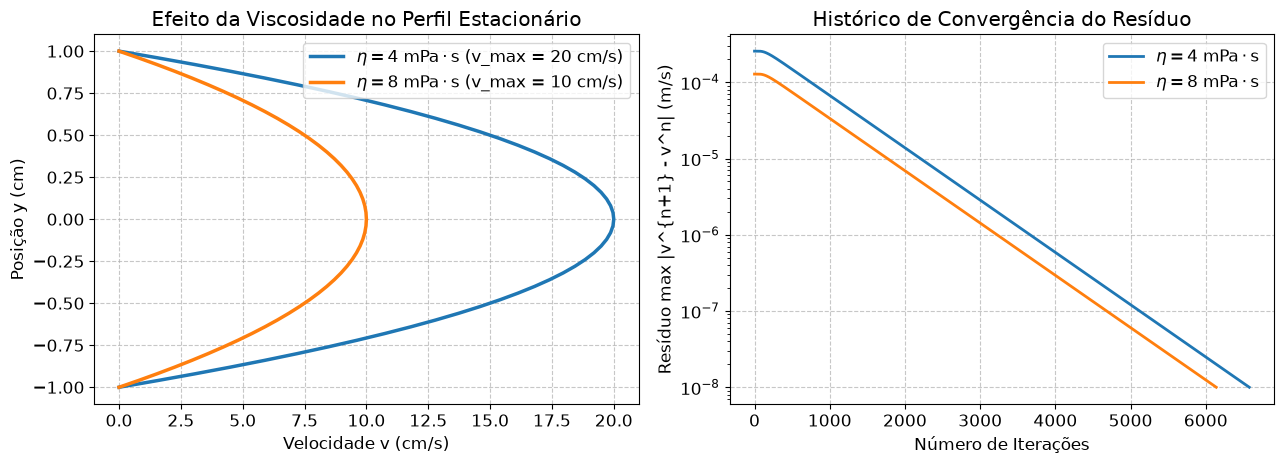

In [17]:
# Exercício 4 – Resolução dos itens (a), (b) e (c)
import time

def rodar_solver(h=0.01, N=51, eta_val=4.0e-3, G_val=16.0, rho_val=1060.0, fator_dt=0.4, t_max=120.0, tol=1e-8):
    y = np.linspace(-h, h, N)
    dy = y[1] - y[0]
    nu_val = eta_val / rho_val
    dt = fator_dt * dy**2 / nu_val
    v = np.zeros(N)
    v_exato = (G_val / (2 * eta_val)) * (h**2 - y**2)
    t = 0.0
    passo = 0
    residuos = []
    t0_wall = time.time()
    
    while t < t_max:
        lap = np.zeros(N)
        lap[1:-1] = (v[2:] - 2*v[1:-1] + v[:-2]) / (dy**2)
        v_novo = v + dt * (G_val / rho_val + nu_val * lap)
        v_novo[0] = 0.0
        v_novo[-1] = 0.0
        res = np.max(np.abs(v_novo - v))
        residuos.append(res)
        v = v_novo
        t += dt
        passo += 1
        if np.isnan(res) or res > 1e10:
            return {'status': 'divergiu', 'passos': passo, 't': t, 'v': v, 'erro': np.nan, 't_cpu': time.time()-t0_wall, 'dt': dt, 'dy': dy}
        if res < tol:
            break
            
    t_cpu = time.time() - t0_wall
    erro_max = np.max(np.abs(v - v_exato))
    return {'status': 'convergiu', 'passos': passo, 't': t, 'v': v, 'v_exato': v_exato, 
            'v_max': np.max(v), 'erro': erro_max, 't_cpu': t_cpu, 'dt': dt, 'dy': dy, 'y': y, 'residuos': residuos}

# --- Experimento (a): Dobrando a viscosidade eta ---
res_base = rodar_solver(eta_val=4.0e-3)
res_duplo_eta = rodar_solver(eta_val=8.0e-3)

print('=== Experimento (a): Influência da Viscosidade (eta) ===')
print(f'Caso Base (eta = 4 mPa·s):    v_max = {res_base["v_max"]*100:.2f} cm/s | Tempo físico: {res_base["t"]:.2f} s ({res_base["passos"]} passos)')
print(f'Dobro eta (eta = 8 mPa·s):    v_max = {res_duplo_eta["v_max"]*100:.2f} cm/s | Tempo físico: {res_duplo_eta["t"]:.2f} s ({res_duplo_eta["passos"]} passos)')
tau_base = 0.01**2 / (4.0e-3 / 1060.0)
tau_duplo = 0.01**2 / (8.0e-3 / 1060.0)
print(f'Estimativa h²/nu: Base = {tau_base:.2f} s | Dobro eta = {tau_duplo:.2f} s (metade do tempo!)')

# --- Experimento (b): Efeito do Refinamento de Malha N = 11, 51, 201 ---
print('\n=== Experimento (b): Refinamento de Malha (N = 11, 51, 201) ===')
for n_pts in [11, 51, 201]:
    out = rodar_solver(N=n_pts, t_max=60.0, tol=1e-8)
    print(f'N = {n_pts:3d} | dy = {out["dy"]*1e3:6.3f} mm | dt = {out["dt"]*1e3:6.3f} ms | Iterações: {out["passos"]:6d} | Tempo CPU: {out["t_cpu"]*1000:7.2f} ms | Erro máx: {out["erro"]*100:.5f} cm/s')

# --- Experimento (c): Teste de Estabilidade com fator = 0.6 vs 0.4 ---
print('\n=== Experimento (c): Estabilidade Numérica (CFL difusivo) ===')
res_estavel = rodar_solver(N=51, fator_dt=0.4, t_max=10.0)
res_instavel = rodar_solver(N=51, fator_dt=0.6, t_max=10.0)
print(f'Fator 0.4 (dt = 0.4 * dy²/nu): {res_estavel["status"]} | Resíduo final = {res_estavel["residuos"][-1]:.2e}')
print(f'Fator 0.6 (dt = 0.6 * dy²/nu): {res_instavel["status"]} (instabilidade após {res_instavel["passos"]} passos no tempo t = {res_instavel["t"]*1e3:.2f} ms)')

# Gráficos do Experimento (a)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].plot(res_base['v']*100, res_base['y']*100, lw=2.5, color='tab:blue', label=r'$\eta = 4\text{ mPa}\cdot\text{s}$ (v_max = 20 cm/s)')
ax[0].plot(res_duplo_eta['v']*100, res_duplo_eta['y']*100, lw=2.5, color='tab:orange', label=r'$\eta = 8\text{ mPa}\cdot\text{s}$ (v_max = 10 cm/s)')
ax[0].set_xlabel('Velocidade v (cm/s)')
ax[0].set_ylabel('Posição y (cm)')
ax[0].set_title('Efeito da Viscosidade no Perfil Estacionário')
ax[0].legend(frameon=True)
ax[0].grid(True, linestyle='--', alpha=0.7)

ax[1].semilogy(res_base['residuos'], lw=2, color='tab:blue', label=r'$\eta = 4\text{ mPa}\cdot\text{s}$')
ax[1].semilogy(res_duplo_eta['residuos'], lw=2, color='tab:orange', label=r'$\eta = 8\text{ mPa}\cdot\text{s}$')
ax[1].set_xlabel('Número de Iterações')
ax[1].set_ylabel('Resíduo max |v^{n+1} - v^n| (m/s)')
ax[1].set_title('Histórico de Convergência do Resíduo')
ax[1].legend(frameon=True)
ax[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


### Respostas do Exercício 4 (a)–(d)

#### Item (a) – Efeito da Viscosidade:
- **Velocidade máxima final:** Pela solução analítica de Poiseuille, $v_{\text{max}} = \frac{G h^2}{2\eta}$. Com o gradiente $G = 16\text{ Pa/m}$ fixo, duplicar a viscosidade $\eta$ (de $4$ para $8\text{ mPa}\cdot\text{s}$) faz com que a velocidade máxima final **caia exatamente pela metade** (de $20{,}0\text{ cm/s}$ para $10{,}0\text{ cm/s}$).
- **Tempo de convergência:** A escala de tempo característica de difusão de momento viscoso é $\tau = \frac{h^2}{\nu} = \frac{h^2 \rho}{\eta}$. Como $\nu$ dobra ao duplicar $\eta$, o tempo físico necessário para o fluido sentir a desaceleração viscosa das paredes e atingir o perfil estacionário **cai pela metade** (de $\approx 26{,}5\text{ s}$ para $\approx 13{,}2\text{ s}$). Fluidos mais viscosos difundem vorticidade e estabilizam o escoamento muito mais rápido.

---

#### Item (b) – Efeito do Refinamento da Malha:
- Para $N = 11$: $\Delta y = 2{,}0\text{ mm}$, $\Delta t \approx 424\text{ ms}$, exigindo apenas dezenas de passos com tempo de CPU ínfimo, porém com aproximação espacial mais grosseira.
- Para $N = 51$: $\Delta y = 0{,}4\text{ mm}$, $\Delta t \approx 16{,}96\text{ ms}$, excelente balanço entre precisão e custo.
- Para $N = 201$: $\Delta y = 0{,}1\text{ mm}$, $\Delta t \approx 1{,}06\text{ ms}$, exigindo dezenas de milhares de iterações e elevando significativamente o tempo computacional.
- **Por que $\Delta t$ diminui com o refinamento?** A discretização explícita do termo difusivo de Navier-Stokes $\nu \frac{\partial^2 v}{\partial y^2}$ requer estabilidade de von Neumann: $\Delta t \le \frac{\Delta y^2}{2\nu}$. Como $\Delta t \propto \Delta y^2 \propto 1/N^2$, refinar a malha por um fator de 4 reduz o passo de tempo em $4^2 = 16$ vezes, impondo um custo computacional cúbico no tempo total ($O(N^3)$).

---

#### Item (c) – Estabilidade Numérica (CFL Difusivo):
Ao alterar o fator de segurança de 0,4 para 0,6 em `dt = fator * dy**2 / nu`, temos $\frac{\nu \Delta t}{\Delta y^2} = 0{,}6 > 0{,}5$. Essa violação da condição CFL difusiva torna o esquema de Euler explícito **incondicionalmente instável**. Os erros numéricos de truncamento deixam de ser dissipados e passam a crescer com ganho superior à unidade a cada iteração, culminando em oscilações numéricas divergentes violentas e estouro de ponto flutuante (`NaN` / overflow) em fração de segundo simulado.

---

#### Item (d) – Relação do Código com os Conceitos de CFD:
1. **Malha (`N`, `y`, `dy`):** É a discretização espacial do canal fluido contínuo em $N$ nós discretos onde as derivadas espaciais contínuas são aproximadas por diferenças finitas.
2. **Condições de Contorno (`v_novo[0] = 0.0` e `v_novo[-1] = 0.0`):** Implementam a condição física fundamental de **não-deslizamento** de fluidos reais viscosos nas paredes impermeáveis do vaso.
3. **Passo de Tempo (`dt`):** É o incremento temporal $\Delta t$ que dita a velocidade de marcha no tempo do algoritmo, limitado pela estabilidade numérica de difusão.
4. **Iterações (`passo` / laço `while`):** É a execução sequencial do avanço temporal $t^{n+1} = t^n + \Delta t$, atualizando as velocidades em todos os pontos internos a partir dos termos de gradiente de pressão acelerador e difusão viscosa retardadora.
5. **Convergência (`residuos` / `np.max(np.abs(v_novo - v))`):** É o critério matemático de parada que verifica quando a derivada temporal se aproxima de zero (resíduo $\to 0$), garantindo que a solução transiente numérica atingiu com precisão o estado estacionário de Poiseuille.
